In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df = pd.read_csv("../generated_data/gamblers_fallacy_results_cleaned.csv")
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Gamblers_Fallacy_4,Gamblers_Fallacy_5,Gamblers_Fallacy_6,Gamblers_Fallacy_7,Gamblers_Fallacy_8,Gamblers_Fallacy_9,Gamblers_Fallacy_10,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,black,black,black,black,black,red,black,deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,red,red,black,red,black,black,red,deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,red,red,red,red,red,black,red,deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,red,red,black,black,black,red,black,deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,black,black,black,red,red,red,red,deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,red,red,black,red,black,black,red,deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,red,red,red,red,red,red,black,deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,red,black,red,red,black,red,red,deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,black,red,red,black,red,red,black,deepseek-v4-flash,no_persona,disabled


In [22]:
gamblers_fallacy_cols = [
    col for col in df.columns
    if col.startswith("Gamblers_")
]

for col in gamblers_fallacy_cols:
    df[col] = df[col].str.lower()
    invalid_mask = ~df[col].isin(["red", "black"])

    if invalid_mask.any():
        print(df.loc[invalid_mask, ["llm", "persona", "thinking", col]])
        print("--------------------")


                    llm      persona  thinking  \
607     deepseek-v4-pro  description  disabled   
650     deepseek-v4-pro  description  disabled   
760     deepseek-v4-pro  description  disabled   
1816    deepseek-v4-pro  raw_persona  disabled   
1880    deepseek-v4-pro  raw_persona  disabled   
3133    deepseek-v4-pro   no_persona  disabled   
3536  deepseek-v4-flash   no_persona  disabled   

                                     Gamblers_Fallacy_0  
607                                       no preference  
650   i have no reason to favour one over the other;...  
760                                                 any  
1816                                       red or black  
1880                                       red or black  
3133  based on the options provided, i would choose ...  
3536                                             black.  
--------------------
                  llm      persona thinking  \
136   deepseek-v4-pro  description  enabled   
1224  deepseek-v4-pr

In [23]:
for col in gamblers_fallacy_cols:

    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r'^[^a-z]*', '', regex=True) # removes any non-alphabetic characters at the beginning of the string
        .str.replace(r'[^a-z]*$', '', regex=True) # removes any non-alphabetic characters at the end of the string
    )

    invalid_mask = ~df[col].isin(["red", "black"])

    if invalid_mask.any():
        print(col)
        print(df.loc[invalid_mask, ["llm", "persona", "thinking", col]])
        print("--------------------")

    df = df.loc[~invalid_mask].copy()
df = df.dropna(subset=gamblers_fallacy_cols).copy()

Gamblers_Fallacy_0
                  llm      persona  thinking  \
607   deepseek-v4-pro  description  disabled   
650   deepseek-v4-pro  description  disabled   
760   deepseek-v4-pro  description  disabled   
1816  deepseek-v4-pro  raw_persona  disabled   
1880  deepseek-v4-pro  raw_persona  disabled   
3133  deepseek-v4-pro   no_persona  disabled   

                                     Gamblers_Fallacy_0  
607                                       no preference  
650   i have no reason to favour one over the other;...  
760                                                 any  
1816                                       red or black  
1880                                       red or black  
3133  based on the options provided, i would choose red  
--------------------
Gamblers_Fallacy_2
                  llm      persona thinking  \
1224  deepseek-v4-pro  raw_persona  enabled   

                                 Gamblers_Fallacy_2  
1224  red": just one word.\n\ni'll answer "red".r

In [6]:
conds = ["llm", "persona", "thinking"]
keys = conds + ["experiment_group"] # analyse red-streak and black-streak groups separately
K = np.arange(1, 11) # streak lengths
BINS = np.arange(1, 7) # human bins: exact lengths 1-5, plus 6+
N_BOOT = 10_000
rng = np.random.default_rng(42)
alpha = 0.05 / df.groupby(conds).ngroups # 12 per group -> 99.58% CIs
lower_ci = alpha / 2
upper_ci = 1 - lower_ci

def ci(bt):
    return np.quantile(bt, [lower_ci, upper_ci], axis=0)

# Human reference: Croson & Sundali (2005), Figure 4.
human_n = np.array([531, 258, 130, 63, 32, 41])
human_p = np.array([255, 131, 67, 36, 21, 35]) / human_n

# 1 = bet against the streak (group 1 saw red streaks, group 2 black)
streak_color = df["experiment_group"].map({1: "red", 2: "black"})
against = np.column_stack([df[f"Gamblers_Fallacy_{k}"] != streak_color for k in K]).astype(int)
red_at_0 = (df["Gamblers_Fallacy_0"] == "red").to_numpy()

# Figure 4 bins: exact streak lengths 1-5, plus 6+ (weighted by how often each length >= 6 occurs)
w6 = (18 / 38) ** (K - 6) * (K >= 6)
to_bins = np.column_stack([K == N for N in range(1, 6)] + [w6 / w6.sum()]).astype(float)

items, bins, summary = [], [], []
for condition, data in df.groupby(keys):
    pos = df.index.get_indexer(data.index)
    X = against[pos]
    idx = rng.integers(0, len(X), size=(N_BOOT, len(X)))    # resampled participants
    lab = dict(zip(keys, condition))
    # 1. per streak length: p = point estimate, p_bt = bootstrap
    p, p_bt = X.mean(0), X[idx].mean(1)
    lo, hi = ci(p_bt)
    items.append(pd.DataFrame({
        **lab, 
        "k": K, 
        "p_against": p, 
        "lower_CI": lo, 
        "upper_CI": hi
        }))

    # 2. comparison with the human bins
    pb, pb_bt = p @ to_bins, p_bt @ to_bins
    lo, hi = ci(pb_bt)
    bins.append(pd.DataFrame({
        **lab,
        "bin": BINS, 
        "p_llm": pb, 
        "lower_CI": lo,
        "upper_CI": hi, 
        "p_human": human_p
        }))

# Red preference without a streak: pool both groups (item 0 is the same question for everyone)
red0 = []
for condition, data in df.groupby(conds):                   
    r = red_at_0[df.index.get_indexer(data.index)]
    idx = rng.integers(0, len(r), size=(N_BOOT, len(r)))  
    lo, hi = ci(r[idx].mean(1))
    red0.append({
        **dict(zip(conds, condition)),
        "n": len(r),
        "red_at_0": r.mean(), 
        "red0_lo": lo, 
        "red0_hi": hi,
        "colour_bias_0": not lo <= .5 <= hi
        })
gf_red0 = pd.DataFrame(red0)
gf_items, gf_bins = pd.concat(items), pd.concat(bins)

In [7]:
gf_bins

,llm,persona,thinking,experiment_group,bin,p_llm,lower_CI,upper_CI,p_human
0,deepseek-v4-flash,description,disabled,1,1,0.006623,0.000000,0.033113,0.480226
1,deepseek-v4-flash,description,disabled,1,2,0.013245,0.000000,0.046358,0.507752
2,deepseek-v4-flash,description,disabled,1,3,0.013245,0.000000,0.046358,0.515385
3,deepseek-v4-flash,description,disabled,1,4,0.013245,0.000000,0.046358,0.571429
4,deepseek-v4-flash,description,disabled,1,5,0.006623,0.000000,0.026490,0.656250
...,...,...,...,...,...,...,...,...,...
1,deepseek-v4-pro,raw_persona,enabled,2,2,0.783784,0.682432,0.878378,0.507752
2,deepseek-v4-pro,raw_persona,enabled,2,3,0.824324,0.736486,0.905405,0.515385
3,deepseek-v4-pro,raw_persona,enabled,2,4,0.797297,0.695946,0.886275,0.571429
4,deepseek-v4-pro,raw_persona,enabled,2,5,0.817568,0.722973,0.898649,0.656250


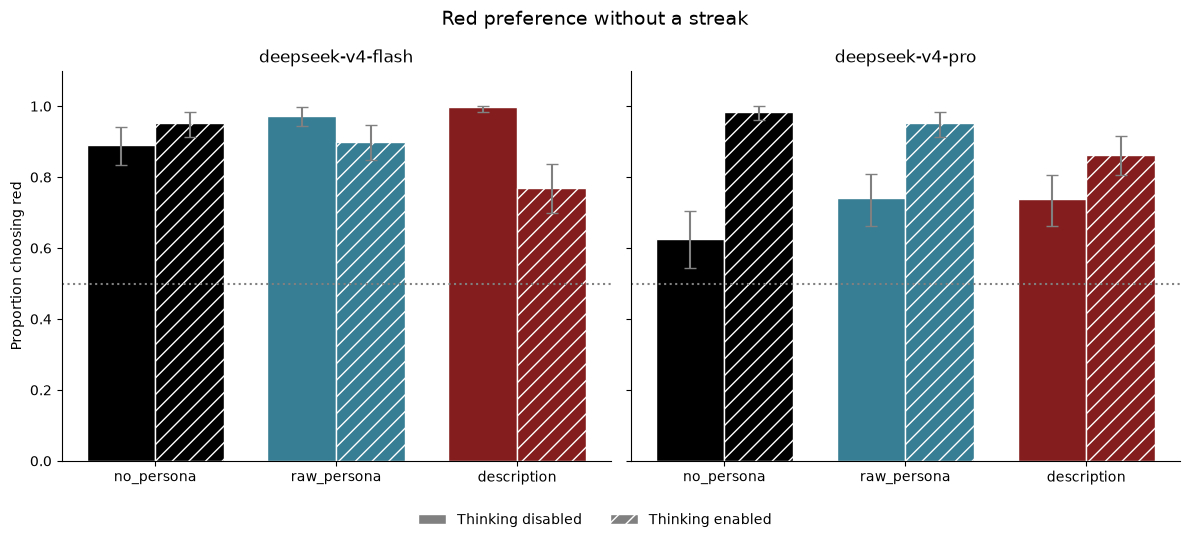

In [ ]:
PERSONAS = ["no_persona", "raw_persona", "description"]
COLORS = dict(zip(PERSONAS, ["#000000", "#377D94", "#841E1E"]))
GROUP_NAMES = {1: "red streak", 2: "black streak"}

def plot_red_at_0(summary):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    x = np.arange(len(PERSONAS))

    for ax, (llm, d) in zip(axes, summary.groupby("llm")):
        # thinking disabled left (plain), enabled right (hatched)
        for offset, hatch, (_, t) in zip([-.19, .19], ["", "//"], d.groupby("thinking")):
            t = t.set_index("persona").loc[PERSONAS]
            ax.bar(
                x + offset, 
                t["red_at_0"], 
                .38, 
                color=COLORS.values(),
                hatch=hatch, 
                edgecolor="white")
            ax.errorbar(
                x + offset, 
                t["red_at_0"],                      
                yerr=[t["red_at_0"] - t["red0_lo"], 
                      t["red0_hi"] - t["red_at_0"]],
                fmt="none", 
                ecolor="grey", 
                capsize=4)
        ax.axhline(.5, color="grey", linestyle=":")
        ax.set(xticks=x, xticklabels=PERSONAS, ylim=(0, 1.1), title=llm)

    axes[0].set_ylabel("Proportion choosing red")
    sns.despine()
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor="grey", hatch=h, edgecolor="white") for h in ["", "//"]]
    fig.legend(handles, ["Thinking disabled", "Thinking enabled"], loc="lower center",
               ncol=2, frameon=False, bbox_to_anchor=(.5, -.08))
    fig.suptitle("Red preference without a streak", fontsize=14)
    fig.tight_layout()

plot_red_at_0(gf_red0)
# plt.savefig("plots/gamblers_fallacy/red_at_0.png", bbox_inches="tight")

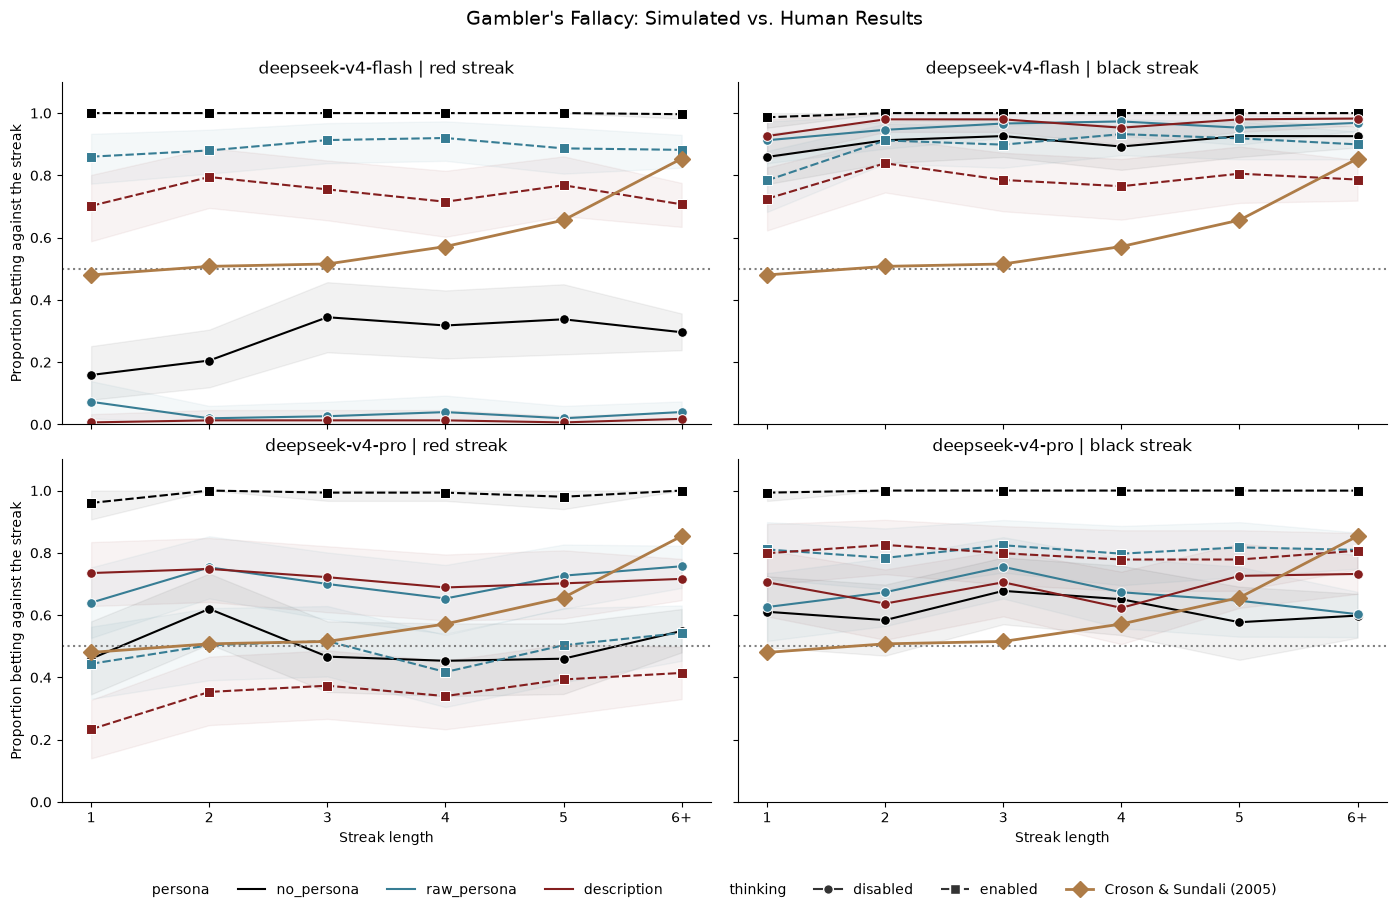

In [ ]:
def plot(data, x, y, xlabel, human):
    sim_plot = sns.relplot(
        data=data, x=x, y=y,
        row="llm", col="experiment_group", 
        kind="line", height=4.5, aspect=1.2,
        hue="persona", hue_order=PERSONAS, palette=COLORS,
        style="thinking", style_order=["disabled", "enabled"],
        markers={"disabled": "o", "enabled": "s"},
        markersize=7, markeredgecolor="white",
        errorbar=None
        )

    # axes_dict maps (llm, group) to its panel, so the order can't get mixed up
    for (llm, group), ax in sim_plot.axes_dict.items():
        d = data[(data["llm"] == llm) & (data["experiment_group"] == group)]
        for (persona, _), c in d.groupby(["persona", "thinking"]):
            ax.fill_between(c[x], c["lower_CI"], c["upper_CI"], color=COLORS[persona], alpha=.05)  # 99.58% bootstrap CI

        ax.axhline(.5, color="grey", linestyle=":")
        human_data, = ax.plot(
            BINS, human, marker="D", markersize=8, linewidth=2,
            color="#ae7c47", zorder=5, label="Croson & Sundali (2005)")
        ax.set_title(f"{llm} | {GROUP_NAMES[group]}")
    sim_plot.set(ylim=(0, 1.1), xticks=data[x].unique(), xlabel=xlabel,
                 ylabel="Proportion betting against the streak")
    sim_plot.set_xticklabels(["1", "2", "3", "4", "5", "6+"])
        # one global legend: seaborn's entries plus the human line
    old = sim_plot._legend
    entries = dict(zip([t.get_text() for t in old.texts], old.legend_handles))
    old.remove()
    sim_plot.add_legend(legend_data={**entries, "Croson & Sundali (2005)": human_data})
    sns.move_legend(sim_plot, "lower center", bbox_to_anchor=(.5, -.02),
                    ncol=len(entries) + 1, title=None, frameon=False)
    sim_plot.figure.subplots_adjust(bottom=.1, top=.9, right=.98)
    sim_plot.figure.suptitle("Gambler's Fallacy: Simulated vs. Human Results", fontsize=14)

    return sim_plot

plot(gf_bins, "bin", "p_llm", "Streak length", human=human_p)
# plt.savefig("plots/gamblers_fallacy/gamblers_fallacy_results.png", bbox_inches="tight")